In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/mymoviedb.csv'

df = pd.read_csv(
    file_path,
    engine='python',
    on_bad_lines='warn'
)

df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [11]:
df.info()
#Release date format to be changes to datetime format

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   object 
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   object 
 5   Vote_Average       9827 non-null   object 
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(1), object(8)
memory usage: 691.8+ KB


In [71]:
df.duplicated().sum()

np.int64(0)

In [72]:
df.describe()

,Popularity
count,9827.000000
mean,40.320570
std,108.874308
min,7.100000
25%,16.127500
50%,21.191000
75%,35.174500
max,5083.954000


In [76]:

df['Release_Date'] = pd.to_datetime(df['Release_Date'])

df['Release_Date'] = df['Release_Date'].dt.year
df['Release_Date'].dtypes



df.describe()
df.head()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9827 non-null   float64
 1   Title              9828 non-null   object 
 2   Overview           9828 non-null   object 
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9826 non-null   float64
 5   Vote_Average       9826 non-null   float64
 6   Original_Language  9827 non-null   object 
 7   Genre              9826 non-null   object 
 8   Poster_Url         9826 non-null   object 
dtypes: float64(4), object(5)
memory usage: 691.8+ KB


In [74]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [77]:
 # Dropping Columns safely
 cols = ['Overview', 'Original_Language', 'Poster_Url']
 df.drop(cols, axis=1, inplace=True, errors='ignore')
 display(df.head())
 df.info()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,1970.0,Spider-Man: No Way Home,5083.954,8940.0,8.3,"Action, Adventure, Science Fiction"
1,1970.0,The Batman,3827.658,1151.0,8.1,"Crime, Mystery, Thriller"
2,1970.0,No Exit,2618.087,122.0,6.3,Thriller
3,1970.0,Encanto,2402.201,5076.0,7.7,"Animation, Comedy, Family, Fantasy"
4,1970.0,The King's Man,1895.511,1793.0,7.0,"Action, Adventure, Thriller, War"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Release_Date  9827 non-null   float64
 1   Title         9828 non-null   object 
 2   Popularity    9827 non-null   float64
 3   Vote_Count    9826 non-null   float64
 4   Vote_Average  9826 non-null   float64
 5   Genre         9826 non-null   object 
dtypes: float64(4), object(2)
memory usage: 461.2+ KB


In [78]:
# user defined fn
def catigorized_col(df, col, labels):
  edges = [df[col].describe()['min'],
          df[col].describe()['25%'],
          df[col].describe()['50%'],
          df[col].describe()['75%'],
          df[col].describe()['max']]

  df[col] = pd.cut(df[col], edges, labels = labels, duplicates= 'drop')
  return df

In [79]:
labels = ['not_popular', 'below_avg', 'average', 'popular']

catigorized_col(df, 'Vote_Average', labels)

df['Vote_Average'].unique()

['popular', 'below_avg', 'average', 'not_popular', NaN]
Categories (4, object): ['not_popular' < 'below_avg' < 'average' < 'popular']

In [80]:
df.head()


,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,"Action, Adventure, Science Fiction"
1,1970.0,The Batman,3827.658,1151.0,popular,"Crime, Mystery, Thriller"
2,1970.0,No Exit,2618.087,122.0,below_avg,Thriller
3,1970.0,Encanto,2402.201,5076.0,popular,"Animation, Comedy, Family, Fantasy"
4,1970.0,The King's Man,1895.511,1793.0,average,"Action, Adventure, Thriller, War"


In [81]:
df['Vote_Average'].value_counts()

,count
Vote_Average,
not_popular,2467
popular,2450
average,2411
below_avg,2398


In [82]:
df.dropna(inplace = True)
df.isna().sum()

,0
Release_Date,0
Title,0
Popularity,0
Vote_Count,0
Vote_Average,0
Genre,0


In [83]:
df['Genre'] = df['Genre'].str.split(', ')
# explode the lists
df = df.explode('Genre').reset_index(drop=True)
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Action
1,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Adventure
2,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Science Fiction
3,1970.0,The Batman,3827.658,1151.0,popular,Crime
4,1970.0,The Batman,3827.658,1151.0,popular,Mystery


In [84]:
# casting column into category
df['Genre'] = df['Genre'].astype('category')
df['Genre'].dtypes

CategoricalDtype(categories=['Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
                  'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
                  'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction',
                  'TV Movie', 'Thriller', 'War', 'Western'],
, ordered=False, categories_dtype=object)

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25551 entries, 0 to 25550
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Release_Date  25551 non-null  float64 
 1   Title         25551 non-null  object  
 2   Popularity    25551 non-null  float64 
 3   Vote_Count    25551 non-null  float64 
 4   Vote_Average  25551 non-null  category
 5   Genre         25551 non-null  category
dtypes: category(2), float64(3), object(1)
memory usage: 849.4+ KB


In [85]:
# setting up seaborn configurations
sns.set_style('whitegrid')


In [86]:
# What is the most frequent genre in the dataset?
df['Genre'].describe()

,Genre
count,25551
unique,19
top,Drama
freq,3715


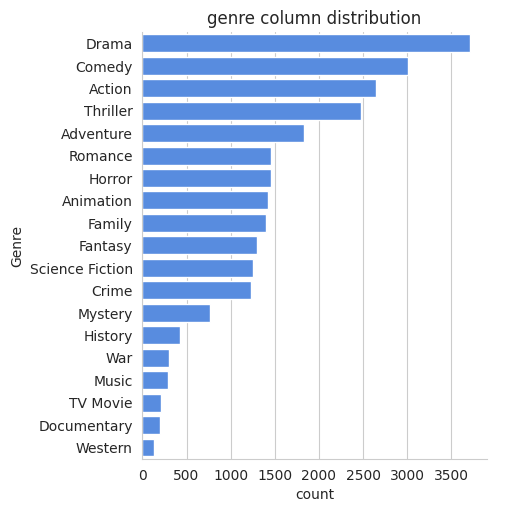

In [45]:
sns.catplot(y = 'Genre', data = df, kind = 'count',
 order = df['Genre'].value_counts().index,
 color = '#4287f5')
plt.title('genre column distribution')
plt.show()

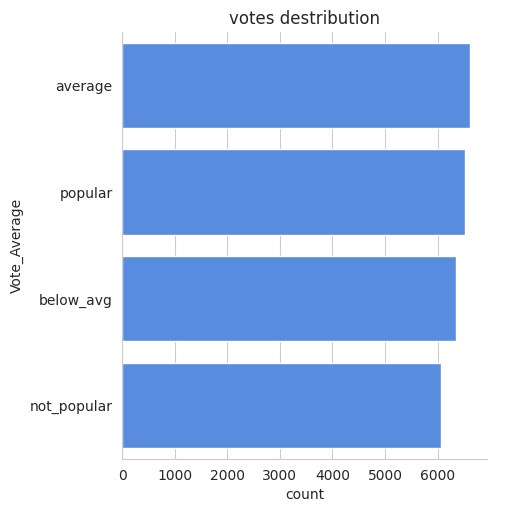

In [46]:
#  What genres has highest votes ?
sns.catplot(y = 'Vote_Average', data = df, kind = 'count',
 order = df['Vote_Average'].value_counts().index,
 color = '#4287f5')
plt.title('votes destribution')
plt.show()

In [47]:
# Q3: What movie got the highest popularity ? what's its genre ?

df[df['Popularity'] == df['Popularity'].max()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Action
1,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Adventure
2,1970.0,Spider-Man: No Way Home,5083.954,8940.0,popular,Science Fiction


In [48]:
# checking max popularity in dataset
df[df['Popularity'] == df['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
25545,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,Music
25546,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,Drama
25547,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,History
25548,1970.0,Threads,13.354,186.0,popular,War
25549,1970.0,Threads,13.354,186.0,popular,Drama
25550,1970.0,Threads,13.354,186.0,popular,Science Fiction


In [87]:
# Q4: What movie got the lowest popularity? what's its genre?
df[df['Popularity'] == df['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
25545,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,Music
25546,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,Drama
25547,1970.0,The United States vs. Billie Holiday,13.354,152.0,average,History
25548,1970.0,Threads,13.354,186.0,popular,War
25549,1970.0,Threads,13.354,186.0,popular,Drama
25550,1970.0,Threads,13.354,186.0,popular,Science Fiction


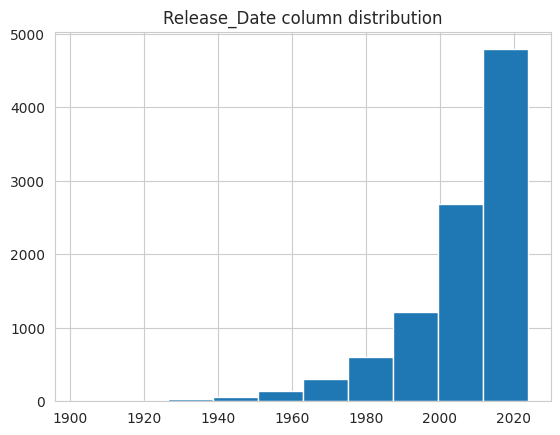

In [92]:
df['Release_Date'].hist()
plt.title('Release_Date column distribution')
plt.show()